# End-to-End Competition Workflow — From Notebook to Kaggle Submission

<hr>

<center>
<div>
<img src="https://raw.githubusercontent.com/davi-moreira/2026F_predictive_analytics_QM474/main/notebooks/figures/mgmt_474_ai_logo_02-modified.png" width="200"/>
</div>
</center>

# <center><a class="tocSkip"></center>
# <center>QM47400 Predictive Analytics</center>
# <center>Professor: Davi Moreira </center>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davi-moreira/2026F_predictive_analytics_QM474/blob/main/notebooks/nb18_competition_workflow_student.ipynb)


> **📋 Participation Reminder:** This notebook contains **2 PAUSE-AND-DO exercises**. Complete both to receive participation credit. The second exercise produces the `submission.csv` you upload to the Kaggle leaderboard.


This notebook presents an **end-to-end predictive modeling workflow**, using our course competition as a practical example. You arrive with the full toolkit behind you — the train/test split discipline, preprocessing pipelines, the logistic baseline, cross-validation with Student's *t* descriptive intervals, the tree ensembles (nb12, nb13), and the model-selection protocol (nb14) — so you run the whole spine end to end in one session: load the data, build a leakage-safe preprocessing pipeline, score a baseline against stronger challengers, commit to a champion worth packaging, and put a `submission.csv` on the leaderboard.

Because the competition requires reproducibility, we fix `RANDOM_SEED = 474` (the course seed). The competition also provides a `test.csv` file without outcome labels. For that reason, `test.csv` is only used at the very end — to generate our final prediction file (`submission.csv`) after we retrain our selected model on the entire training set.

The modeling process follows this structure:

* `train.csv` is split once into an 80% **training set** (for 5-fold cross-validation and model selection) and a 20% **held-out test set** (for one unbiased check of the champion).
* Once the champion is selected and checked on the held-out set, the two splits are **merged** and the model is **retrained on the entire `train.csv`** before generating predictions for `test.csv`.

Our workflow is organized in the following sequence. For each step we also provide a **Gemini Prompt** suggestion you can copy into Gemini to request the corresponding Python code.

- Step 0 — Setup, configuration, and imports
- Step 1 — Data loading and sanity checks
- Step 2 — Exploratory Data Analysis (EDA)
- Step 3 — Data preparation and feature engineering
- Step 4 — Baseline model (Logistic Regression)
- Step 5 — More complex models (LASSO, Random Forest, Gradient Boosting)
- Step 6 — Compare models with visualization
- Step 7 — Model selection and rationale
- Step 8 — Evaluate the champion on the held-out test set
- Step 9 — Final training on the full (merged) training data
- Step 10 — Predict on the competition test set and export `submission.csv`
- Step 99 — Reporting and reproducibility

## Step 0 — Setup, configuration, and imports

> 💡 **Gemini Prompt:** "Write a setup cell for a binary-classification competition workflow. Import pandas, numpy, matplotlib.pyplot, joblib, `scipy.stats`, and from scikit-learn: `ColumnTransformer`, `Pipeline`, `StandardScaler`, `OneHotEncoder`, `SimpleImputer`, `StratifiedKFold`, `cross_val_score`, `cross_val_predict`, `GridSearchCV`, `LogisticRegression`, `RandomForestClassifier`, `GradientBoostingClassifier`, `roc_auc_score`, and `classification_report`. Set `RANDOM_SEED = 474`, seed numpy, set the figure size to (10, 6) and display precision to 3, create `cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)` so every model in this notebook is scored on the identical folds, set the practical-equivalence margin `MARGIN = 0.01` — the smallest ROC-AUC gap that would change the business decision, declared here before any model is scored — then define a helper `ci95(mean, sd, k=5)` returning the Student's-t approximate 95% interval half-width and bounds."
>
> **After running, verify:**
> - The cell prints `RANDOM_SEED = 474` with no import errors.
> - `ci95(0.80, 0.02)` returns a half-width near 0.025 (the t-multiplier for df=4 is \~2.776).
> - `cv_strat` has `shuffle=True, random_state=RANDOM_SEED`, and `MARGIN = 0.01` exists — Steps 4–7 use those folds and Steps 7–8 use the margin.
> - `cv_strat` has `shuffle=True, random_state=RANDOM_SEED`, and `MARGIN = 0.01` exists — Steps 4–8 depend on both.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import scipy.stats as stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, classification_report

# Set random seeds for reproducibility
RANDOM_SEED = 474
np.random.seed(RANDOM_SEED)

# Configure plotting and display settings
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.precision", 3)

# Define cross-validation strategy
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Practical equivalence margin
MARGIN = 0.01

# Print configuration confirmation
print(f"RANDOM_SEED = {RANDOM_SEED}")

def ci95(mean, sd, k=5):
    """Calculates Student's-t approximate 95% interval half-width and bounds.

    For k=5, df=4, critical t is approximately 2.776.
    """
    df = k - 1
    t_crit = stats.t.ppf(0.975, df=df)
    half_width = t_crit * (sd / np.sqrt(k))
    lower_bound = mean - half_width
    upper_bound = mean + half_width
    return half_width, (lower_bound, upper_bound)

# Sanity check validation
hw, bounds = ci95(0.80, 0.02)
print(f"Sanity check ci95(0.80, 0.02): half-width = {hw:.4f}, bounds = ({bounds[0]:.4f}, {bounds[1]:.4f})")

RANDOM_SEED = 474
Sanity check ci95(0.80, 0.02): half-width = 0.0248, bounds = (0.7752, 0.8248)


## Step 1 — Data loading and sanity checks

First, **upload the competition data to Colab.** Open the **Files** panel (the folder icon in the left sidebar), click the upload button, and add `train.csv` and `test.csv` from the case-competition starter pack. Uploaded files land in Colab's working directory (`/content`), so we can load them by name.

We load the labeled `train.csv` and the unlabeled `test.csv`, then run the sanity checks that keep the rest of the notebook honest: shapes, dtypes, missing-value counts, and the target class balance. Sections 2–8 work strictly on the labeled training data; `test.csv` is opened only in Step 9 to generate the submission.

> 💡 **Gemini Prompt:** "After uploading `train.csv` and `test.csv` to the Colab Files panel, load them from the current working directory into `df_train_full` and `df_test_kaggle`. The target column is `Exited`. Raise a clear `FileNotFoundError` (naming `os.getcwd()`) if a file is missing. Print both shapes, the dtypes, missing-value counts, and the target class balance for the training set, and confirm the only column difference between train and test is the target."
>
> **After running, verify:**
> - Both files load without dtype warnings (or the warning is named in your README).
> - The target balance is around 0.20 — the dataset is moderately imbalanced.
> - `set(train.columns) - set(test.columns)` is exactly `{'Exited'}`.

In [17]:
import os
import pandas as pd

train_path = "train.csv"
test_path = "test.csv"

# Raise FileNotFoundError naming os.getcwd() if files are missing
if not os.path.exists(train_path) or not os.path.exists(test_path):
    raise FileNotFoundError(
        f"Required files not found in working directory: {os.getcwd()}. "
        f"Please verify that 'train.csv' and 'test.csv' are uploaded."
    )

# Load datasets
df_train_full = pd.read_csv(train_path)
df_test_kaggle = pd.read_csv(test_path)

# Print shapes
print(f"df_train_full shape: {df_train_full.shape}")
print(f"df_test_kaggle shape: {df_test_kaggle.shape}\n")

# Confirm the only column difference between train and test is the target 'Exited'
train_cols = set(df_train_full.columns)
test_cols = set(df_test_kaggle.columns)
col_diff = train_cols - test_cols
print(f"Columns in train but not in test: {col_diff}")
assert col_diff == {'Exited'}, "Error: Column difference must be exactly the target 'Exited'."

# Print target class balance
print("\n--- Target ('Exited') Class Balance ---")
print(df_train_full['Exited'].value_counts(normalize=True))
print(df_train_full['Exited'].value_counts())

# Print missing value counts
print("\n--- Missing-Value Counts (Train) ---")
print(df_train_full.isnull().sum())

print("\n--- Data Types ---")
print(df_train_full.dtypes)

df_train_full shape: (15000, 14)
df_test_kaggle shape: (10000, 13)

Columns in train but not in test: {'Exited'}

--- Target ('Exited') Class Balance ---
Exited
0.0    0.797
1.0    0.203
Name: proportion, dtype: float64
Exited
0.0    11962
1.0     3038
Name: count, dtype: int64

--- Missing-Value Counts (Train) ---
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

--- Data Types ---
id                   int64
CustomerId         float64
Surname             object
CreditScore        float64
Geography           object
Gender              object
Age                float64
Tenure             float64
Balance            float64
NumOfProducts      float64
HasCrCard          float64
IsActiveMember     float64
EstimatedSalary    float64
Exite

## Step 2 — Exploratory Data Analysis (EDA)

A compact three-panel EDA snapshot — class balance, missingness, and the numeric features most correlated with the target — is enough to confirm the dataset matches the rubric's description and to flag any column to drop or transform. We use matplotlib throughout, matching the course's plotting convention from nb01 onward.

> 💡 **Gemini Prompt:** "From `df_train_full`, make one matplotlib figure with three subplots: (a) `Exited` value counts as a bar chart; (b) per-column missing-value counts, sorted descending, top 10; (c) absolute correlation of each numeric column with `Exited`, top 10. Use `plt.tight_layout()`."
>
> **After running, verify:**
> - The class-balance panel shows the \~20% minority class.
> - The correlation panel ranks the usual churn drivers (e.g., `Age`, `Balance`, `NumOfProducts`) near the top.

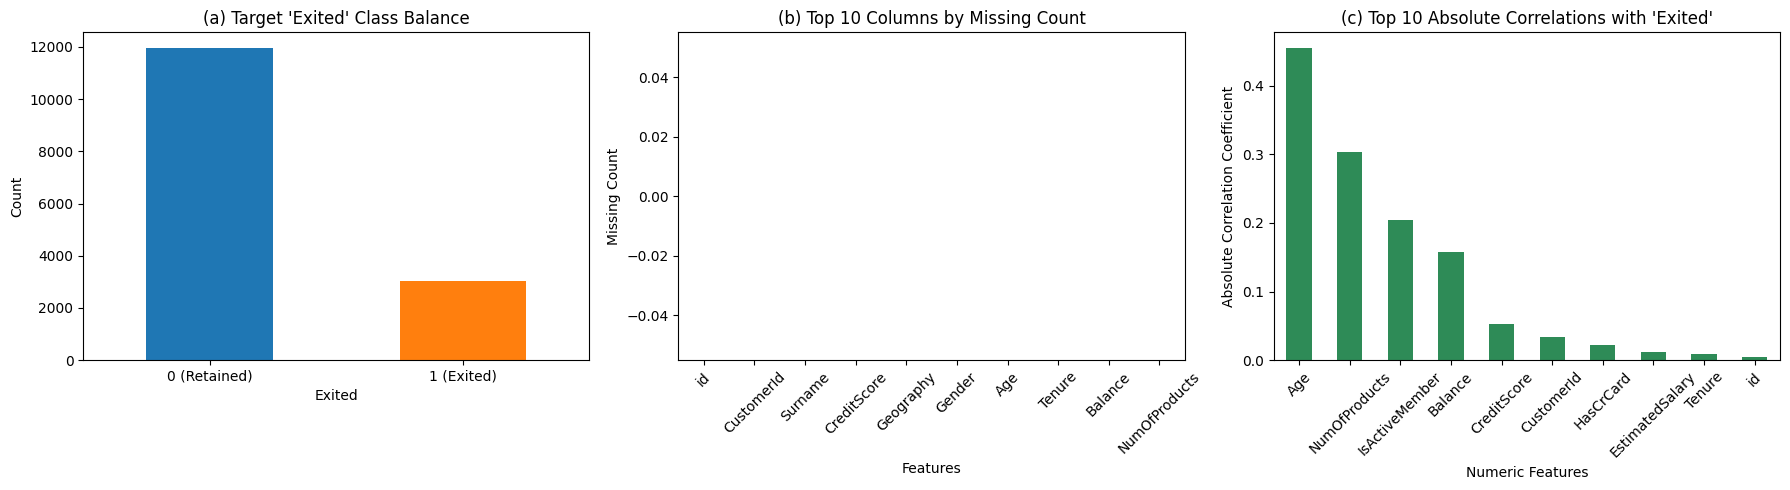

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Create a figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot (a): Exited value counts as a bar chart
exited_counts = df_train_full['Exited'].value_counts()
exited_counts.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title("(a) Target 'Exited' Class Balance")
axes[0].set_xlabel("Exited")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["0 (Retained)", "1 (Exited)"], rotation=0)

# Subplot (b): Per-column missing-value counts (sorted descending, top 10)
missing_counts = df_train_full.isnull().sum().sort_values(ascending=False).head(10)
missing_counts.plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title("(b) Top 10 Columns by Missing Count")
axes[1].set_xlabel("Features")
axes[1].set_ylabel("Missing Count")
axes[1].tick_params(axis='x', rotation=45)

# Subplot (c): Absolute correlation of numeric columns with Exited (top 10)
numeric_cols = df_train_full.select_dtypes(include=[np.number])
correlations = numeric_cols.corr()['Exited'].abs().sort_values(ascending=False)
# Drop 'Exited' itself so we only view features
correlations_features = correlations.drop('Exited', errors='ignore').head(10)
correlations_features.plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title("(c) Top 10 Absolute Correlations with 'Exited'")
axes[2].set_xlabel("Numeric Features")
axes[2].set_ylabel("Absolute Correlation Coefficient")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Step 3 — Data preparation and feature engineering

We wrap every column transformation inside a `ColumnTransformer` (nb02), so the exact logic that fits on training data is the logic that predicts on the Kaggle test set. Numeric columns are median-imputed and standardized; categorical columns are mode-imputed and one-hot encoded with `handle_unknown='ignore'`. We also drop identifier columns so they never leak into the model.

We then make **one stratified split** of `train.csv` (nb01/nb03): 80% becomes the **training set** used for cross-validation and model selection, and 20% becomes a **held-out test set** we touch only once, at the end, to get an unbiased estimate of the champion's performance. After selection we merge the two back together and refit on all of `train.csv` before predicting the competition `test.csv`.

> 💡 **Gemini Prompt:** "Write `build_preprocessor(df, target='Exited')` that drops identifier-like columns (`RowNumber`, `CustomerId`, `Surname`, `id`) if present, then returns a `ColumnTransformer`: numeric columns get median `SimpleImputer` + `StandardScaler`; categorical columns get most-frequent `SimpleImputer` + `OneHotEncoder(handle_unknown='ignore')`. Build the full feature matrix `X_full, y_full`, then make one stratified 80/20 `train_test_split` into `X_train, X_holdout, y_train, y_holdout` with `random_state=474`."
>
> **After running, verify:**
> - The categorical list includes `Geography` and `Gender`; identifiers are excluded.
> - `X_train` has \~80% of the rows and `X_holdout` \~20%, both with the same class balance (stratified).

In [19]:
from sklearn.model_selection import train_test_split

def build_preprocessor(df, target='Exited'):
    """Creates a ColumnTransformer preprocessing pipeline.

    Drops identifier-like columns if present, identifies numeric and categorical
    features, and applies median imputation + scaling to numeric features and
    most-frequent imputation + one-hot encoding to categorical features.
    """
    # Drop identifier-like columns if they are present in the DataFrame
    cols_to_drop = ['RowNumber', 'CustomerId', 'Surname', 'id']
    existing_drops = [col for col in cols_to_drop if col in df.columns]
    df_cleaned = df.drop(columns=existing_drops + [target], errors='ignore')

    # Identify feature types
    numeric_features = df_cleaned.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = df_cleaned.select_dtypes(exclude=[np.number]).columns.tolist()

    # Define numeric transformer
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Define categorical transformer
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Bundle preprocessing for numeric and categorical data
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ]
    )

    return preprocessor

# Separate features and target from df_train_full
X_full = df_train_full.drop(columns=['Exited'])
y_full = df_train_full['Exited']

# Create the stratified 80/20 train/test split
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    stratify=y_full,
    random_state=RANDOM_SEED
)

print(f"X_train shape: {X_train.shape}")
print(f"X_holdout shape: {X_holdout.shape}")
print(f"y_train balance:\n{y_train.value_counts(normalize=True)}")
print(f"y_holdout balance:\n{y_holdout.value_counts(normalize=True)}")

X_train shape: (12000, 13)
X_holdout shape: (3000, 13)
y_train balance:
Exited
0.0    0.797
1.0    0.203
Name: proportion, dtype: float64
y_holdout balance:
Exited
0.0    0.797
1.0    0.203
Name: proportion, dtype: float64


## Step 4 — Baseline model (Logistic Regression)

We anchor the comparison with a **logistic-regression baseline** (nb06), evaluated with 5-fold stratified cross-validation on the training data only (nb08). We report the mean ROC-AUC with its **Student's *t* approximate 95% interval** — `mean ± t_crit · sd / √k` — exactly the arithmetic the course has used since nb08, and we read it for what it is: a *descriptive* summary of how much the score moved from fold to fold. It is not a guarantee about the model's true performance, and it leans optimistic — adjacent folds train on mostly the same rows, so their scores are correlated and `sd / √k` understates the real variability. Treat the width you see as a floor on the uncertainty, not a ceiling. Out-of-fold predictions give an honest `classification_report` in which every prediction comes from a fold that never saw that row during fitting.

> 💡 **Gemini Prompt:** "Build a pipeline of `build_preprocessor` + `LogisticRegression(max_iter=2000, class_weight='balanced')`. Score it with `cross_val_score(..., scoring='roc_auc', cv=cv_strat)`, keep the five per-fold scores in an array `log_scores`, report the mean ROC-AUC and its Student's-t approximate 95% interval via `ci95`, then use `cross_val_predict` to print a `classification_report`."
>
> **After running, verify:**
> - Baseline CV ROC-AUC lands near 0.88 with the course data and seed.
> - The classification report's recall on the churn class reflects the `class_weight='balanced'` setting.

In [20]:
# Build baseline pipeline
preprocessor = build_preprocessor(X_train)
baseline_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_SEED))
])

# Score with stratified 5-fold cross-validation
log_scores = cross_val_score(
    baseline_pipe,
    X_train,
    y_train,
    scoring='roc_auc',
    cv=cv_strat,
    n_jobs=-1
)

# Compute mean, standard deviation, and Student's-t 95% confidence interval
log_mean = np.mean(log_scores)
log_sd = np.std(log_scores, ddof=1)
log_hw, log_bounds = ci95(log_mean, log_sd, k=5)

print("--- Logistic Regression Baseline CV ROC-AUC ---")
print(f"Fold scores: {log_scores}")
print(f"Mean ROC-AUC: {log_mean:.4f}")
print(f"Standard Deviation: {log_sd:.4f}")
print(f"Student's-t 95% Interval: {log_mean:.4f} ± {log_hw:.4f} (bounds: {log_bounds[0]:.4f} to {log_bounds[1]:.4f})")

# Generate out-of-fold predictions and print classification report
y_pred_oof = cross_val_predict(
    baseline_pipe,
    X_train,
    y_train,
    cv=cv_strat,
    n_jobs=-1
)

print("\n--- Out-of-Fold Classification Report ---")
print(classification_report(y_train, y_pred_oof))

--- Logistic Regression Baseline CV ROC-AUC ---
Fold scores: [0.88561971 0.89500905 0.86024678 0.88502415 0.89124214]
Mean ROC-AUC: 0.8834
Standard Deviation: 0.0136
Student's-t 95% Interval: 0.8834 ± 0.0169 (bounds: 0.8665 to 0.9003)

--- Out-of-Fold Classification Report ---
              precision    recall  f1-score   support

         0.0       0.94      0.82      0.88      9570
         1.0       0.53      0.79      0.64      2430

    accuracy                           0.82     12000
   macro avg       0.74      0.81      0.76     12000
weighted avg       0.86      0.82      0.83     12000



## Step 5 — More complex models (LASSO, Random Forest, Gradient Boosting)

Building on the logistic baseline, we challenge it with three models the course has already taught: a **LASSO (L1-penalized) logistic regression** (nb05), a **Random Forest** (nb12), and a **Gradient Boosting** classifier (nb13). Each is tuned with a small `GridSearchCV` over the hyperparameters that mattered in those notebooks (nb09), and each is scored on the same 5-fold stratified CV so the ROC-AUC numbers are directly comparable. We keep every model inside the same preprocessing pipeline to prevent leakage.

### Step 5.1 — LASSO (L1-penalized logistic regression)

> 💡 **Gemini Prompt:** "Build a pipeline of `build_preprocessor` + `LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced')`. Tune `C` over `[0.01, 0.1, 1, 10]` with `GridSearchCV(scoring='roc_auc', cv=cv_strat)`. Report the best `C`, the best mean ROC-AUC, and its Student's-t approximate 95% interval using the fold standard deviation from `cv_results_`."
>
> **After running, verify:**
> - A best `C` is printed and the LASSO CV ROC-AUC is in the same ballpark as the logistic baseline.
> - Small `C` (stronger L1) zeros out some coefficients — the regularization lesson from nb05.

In [21]:
# Build LASSO pipeline
preprocessor = build_preprocessor(X_train)
lasso_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', random_state=RANDOM_SEED))
])

# Set hyperparameter grid for C
param_grid = {'classifier__C': [0.01, 0.1, 1, 10]}

# Configure GridSearchCV
lasso_search = GridSearchCV(
    lasso_pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strat,
    n_jobs=-1
)

# Fit GridSearchCV on the training data
lasso_search.fit(X_train, y_train)

# Extract best results
best_c = lasso_search.best_params_['classifier__C']
best_index = lasso_search.best_index_

# Retrieve fold scores for the best parameter setting
lasso_scores = np.array([
    lasso_search.cv_results_[f'split{i}_test_score'][best_index]
    for i in range(5)
])

# Compute mean, standard deviation (ddof=1), and Student's-t 95% confidence interval
lasso_mean = lasso_search.best_score_
lasso_sd = np.std(lasso_scores, ddof=1)
lasso_hw, lasso_bounds = ci95(lasso_mean, lasso_sd, k=5)

print("--- LASSO L1 Logistic Regression CV ROC-AUC ---")
print(f"Best C: {best_c}")
print(f"Fold scores: {lasso_scores}")
print(f"Mean ROC-AUC: {lasso_mean:.4f}")
print(f"Standard Deviation: {lasso_sd:.4f}")
print(f"Student's-t 95% Interval: {lasso_mean:.4f} ± {lasso_hw:.4f} (bounds: {lasso_bounds[0]:.4f} to {lasso_bounds[1]:.4f})")

--- LASSO L1 Logistic Regression CV ROC-AUC ---
Best C: 1
Fold scores: [0.88560896 0.8950456  0.86024141 0.88503382 0.89125074]
Mean ROC-AUC: 0.8834
Standard Deviation: 0.0136
Student's-t 95% Interval: 0.8834 ± 0.0169 (bounds: 0.8665 to 0.9003)


### Step 5.2 — Random Forest

> 💡 **Gemini Prompt:** "Build a pipeline of `build_preprocessor` + `RandomForestClassifier(class_weight='balanced', n_jobs=-1)`. Tune `n_estimators` over `[200]`, `max_depth` over `[3, 5, None]`, and `max_features` over `['sqrt', 0.5]` with `GridSearchCV(scoring='roc_auc', cv=cv_strat)`. Report the best parameters, the best mean ROC-AUC, and its Student's-t approximate 95% interval."
>
> **After running, verify:**
> - The forest's CV ROC-AUC typically edges above the logistic baseline.
> - The best `max_features` is `'sqrt'` or `0.5` — the de-correlation knob from nb12.

In [22]:
# Build Random Forest pipeline
preprocessor = build_preprocessor(X_train)
rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1))
])

# Set hyperparameter grid
rf_param_grid = {
    'classifier__n_estimators': [200],
    'classifier__max_depth': [3, 5, None],
    'classifier__max_features': ['sqrt', 0.5]
}

# Configure GridSearchCV
rf_search = GridSearchCV(
    rf_pipe,
    param_grid=rf_param_grid,
    scoring='roc_auc',
    cv=cv_strat,
    n_jobs=-1
)

# Fit GridSearchCV on the training data
rf_search.fit(X_train, y_train)

# Extract best results
best_rf_params = rf_search.best_params_
best_rf_index = rf_search.best_index_

# Retrieve fold scores for the best parameter setting
rf_scores = np.array([
    rf_search.cv_results_[f'split{i}_test_score'][best_rf_index]
    for i in range(5)
])

# Compute mean, standard deviation (ddof=1), and Student's-t 95% confidence interval
rf_mean = rf_search.best_score_
rf_sd = np.std(rf_scores, ddof=1)
rf_hw, rf_bounds = ci95(rf_mean, rf_sd, k=5)

print("--- Random Forest CV ROC-AUC ---")
print(f"Best parameters: {best_rf_params}")
print(f"Fold scores: {rf_scores}")
print(f"Mean ROC-AUC: {rf_mean:.4f}")
print(f"Standard Deviation: {rf_sd:.4f}")
print(f"Student's-t 95% Interval: {rf_mean:.4f} ± {rf_hw:.4f} (bounds: {rf_bounds[0]:.4f} to {rf_bounds[1]:.4f})")

--- Random Forest CV ROC-AUC ---
Best parameters: {'classifier__max_depth': 5, 'classifier__max_features': 0.5, 'classifier__n_estimators': 200}
Fold scores: [0.92853234 0.93976859 0.92237294 0.92446926 0.92471329]
Mean ROC-AUC: 0.9280
Standard Deviation: 0.0070
Student's-t 95% Interval: 0.9280 ± 0.0086 (bounds: 0.9193 to 0.9366)


### Step 5.3 — Gradient Boosting

> 💡 **Gemini Prompt:** "Build a pipeline of `build_preprocessor` + `GradientBoostingClassifier()`. Tune `n_estimators` over `[200]`, `learning_rate` over `[0.05, 0.2]`, and `max_depth` over `[3]` with `GridSearchCV(scoring='roc_auc', cv=cv_strat)`. Report the best parameters, the best mean ROC-AUC, and its Student's-t approximate 95% interval."
>
> **After running, verify:**
> - The boosted model is usually the top or near-top mean ROC-AUC.
> - A smaller `learning_rate` with enough trees is the disciplined setting from nb13.

In [23]:
# Build Gradient Boosting pipeline
preprocessor = build_preprocessor(X_train)
gb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_SEED))
])

# Set hyperparameter grid
gb_param_grid = {
    'classifier__n_estimators': [200],
    'classifier__learning_rate': [0.05, 0.2],
    'classifier__max_depth': [3]
}

# Configure GridSearchCV
gb_search = GridSearchCV(
    gb_pipe,
    param_grid=gb_param_grid,
    scoring='roc_auc',
    cv=cv_strat,
    n_jobs=-1
)

# Fit GridSearchCV on the training data
gb_search.fit(X_train, y_train)

# Extract best results
best_gb_params = gb_search.best_params_
best_gb_index = gb_search.best_index_

# Retrieve fold scores for the best parameter setting
gb_scores = np.array([
    gb_search.cv_results_[f'split{i}_test_score'][best_gb_index]
    for i in range(5)
])

# Compute mean, standard deviation (ddof=1), and Student's-t 95% confidence interval
gb_mean = gb_search.best_score_
gb_sd = np.std(gb_scores, ddof=1)
gb_hw, gb_bounds = ci95(gb_mean, gb_sd, k=5)

print("--- Gradient Boosting CV ROC-AUC ---")
print(f"Best parameters: {best_gb_params}")
print(f"Fold scores: {gb_scores}")
print(f"Mean ROC-AUC: {gb_mean:.4f}")
print(f"Standard Deviation: {gb_sd:.4f}")
print(f"Student's-t 95% Interval: {gb_mean:.4f} ± {gb_hw:.4f} (bounds: {gb_bounds[0]:.4f} to {gb_bounds[1]:.4f})")

--- Gradient Boosting CV ROC-AUC ---
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Fold scores: [0.93601081 0.9437575  0.93127099 0.93203104 0.92927358]
Mean ROC-AUC: 0.9345
Standard Deviation: 0.0057
Student's-t 95% Interval: 0.9345 ± 0.0071 (bounds: 0.9273 to 0.9416)


## Step 6 — Compare models with visualization

We assemble the four candidates into one comparison table (mean ROC-AUC, fold SD, and the Student's-*t* interval half-width) and plot them with error bars. Those bars describe how much each model's score moved across folds, and that is all they do: two bars overlapping does **not** mean the two models perform the same, because each bar still carries the fold-to-fold swings that both models share. A real comparison needs the two candidates' scores on the *identical* folds — which is exactly what we have, because every model above was scored with the `cv_strat` splitter seeded in Step 0 — so we also keep each model's five per-fold ROC-AUC values here and let Step 7 subtract them fold by fold. One honesty note before you read the chart: the three tuned models' fold scores belong to the hyperparameter setting that won a search on these same five folds, so part of any small edge over the untuned logistic baseline is the search itself — one more reason Step 7's margin, not a glance at the bars, makes the call.

> 💡 **Gemini Prompt:** "Build a DataFrame `results` with one row per model (`Logistic`, `LASSO`, `Random Forest`, `Gradient Boosting`) holding `roc_auc_mean`, `roc_auc_sd`, and the Student's-t approximate 95% half-width from `ci95`. Also build a dict `fold_scores` mapping each model name to its five per-fold ROC-AUC values — the `log_scores` array from Step 4 for the logistic baseline, and the `split0_test_score` through `split4_test_score` entries of `cv_results_` at `best_index_` for each tuned model. Sort `results` by mean descending and draw a matplotlib bar chart of the means with the half-width as symmetric error bars."
>
> **After running, verify:**
> - Four bars appear, each with an error bar.
> - The table is sorted with the highest-mean model first.
> - `fold_scores` holds five values per model, all produced by the same `cv_strat` splitter.

--- Cross-Validation Model Comparison Summary ---
            Model  roc_auc_mean  roc_auc_sd  ci95_half_width
Gradient Boosting         0.934       0.006            0.007
    Random Forest         0.928       0.007            0.009
            LASSO         0.883       0.014            0.017
         Logistic         0.883       0.014            0.017


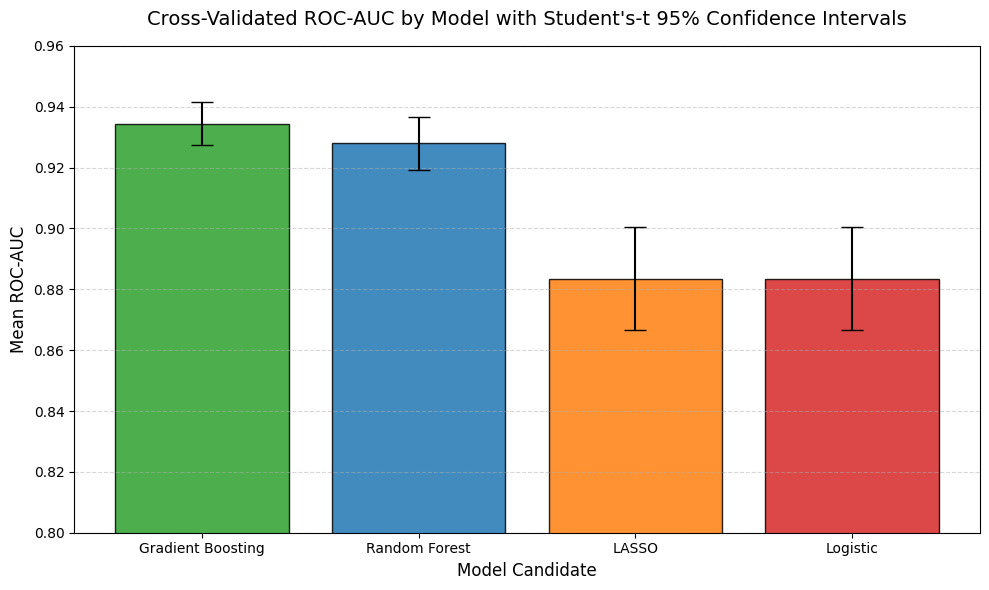

In [24]:
# Build fold_scores dictionary
fold_scores = {
    'Logistic': log_scores,
    'LASSO': lasso_scores,
    'Random Forest': rf_scores,
    'Gradient Boosting': gb_scores
}

# Calculate intervals
log_hw, _ = ci95(log_mean, log_sd, k=5)
lasso_hw, _ = ci95(lasso_mean, lasso_sd, k=5)
rf_hw, _ = ci95(rf_mean, rf_sd, k=5)
gb_hw, _ = ci95(gb_mean, gb_sd, k=5)

# Create the results summary DataFrame
results = pd.DataFrame({
    'Model': ['Logistic', 'LASSO', 'Random Forest', 'Gradient Boosting'],
    'roc_auc_mean': [log_mean, lasso_mean, rf_mean, gb_mean],
    'roc_auc_sd': [log_sd, lasso_sd, rf_sd, gb_sd],
    'ci95_half_width': [log_hw, lasso_hw, rf_hw, gb_hw]
})

# Sort results descending by mean performance
results = results.sort_values(by='roc_auc_mean', ascending=False).reset_index(drop=True)

print("--- Cross-Validation Model Comparison Summary ---")
print(results.to_string(index=False))

# Plot bar chart with symmetric confidence interval error bars
plt.figure(figsize=(10, 6))
plt.bar(
    results['Model'],
    results['roc_auc_mean'],
    yerr=results['ci95_half_width'],
    capsize=8,
    color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'],
    edgecolor='black',
    alpha=0.85
)
plt.title("Cross-Validated ROC-AUC by Model with Student's-t 95% Confidence Intervals", fontsize=14, pad=15)
plt.ylabel("Mean ROC-AUC", fontsize=12)
plt.xlabel("Model Candidate", fontsize=12)
plt.ylim(0.80, 0.96)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Step 7 — Model selection and rationale

We pick the champion with the same **paired-difference → parsimony** rule the model-selection protocol introduced in nb14, and it runs in three moves. First, the yardstick is already fixed: `MARGIN = 0.01` from Step 0 — the smallest ROC-AUC gap that would change the business decision — declared before a single model was scored, so the results cannot tempt us into moving it. Second, we line up the top model and its runner-up on the **identical** folds — same `cv_strat` splitter, same seed, so both candidates saw exactly the same five train/score splits — and subtract fold by fold: `d_i = top_i - runner_i`. Subtracting inside each fold removes the fold-to-fold swings the two models share, which is much of what makes both error bars wide; what remains is the head-to-head gap, and it still carries Step 4's caveat — the five differences come from overlapping training sets too, so the `ci95` interval on their mean is descriptive, not exact, and the decision below never asks whether that interval covers zero. Third, the verdict has **three** possible outcomes, not two. If all five differences share one sign *and* their mean clears the margin, the top model won on every slice of the data by a gap big enough to matter — a real difference, and the top model is the champion. If the differences change sign across folds, the two models trade places depending on which rows they saw: the comparison names **no winner**, and with no evidence for the heavier model we keep the simpler one. If the differences share a sign but their mean sits inside the margin, the two are **practically equivalent** — the gap is too small to matter here — and the **simpler** model wins: interpretability and deployment cost break the tie. This is the discipline that stops us from chasing a fractionally higher leaderboard score with a heavier model we cannot defend.

> **A question that often comes up here:** *"What if four folds favor the top model by a lot and one fold barely favors the runner-up — doesn't the big average gap settle it?"* Under this rule, no: one flipped fold means the ranking depended on which rows landed in which fold, and with only five folds a single flip is a real sign the comparison is unstable, so it names no winner and you keep the simpler model. That can feel strict when the average gap looks large, but consider what the strictness protects you from — crowning a champion on a fold pattern that a different shuffle could reverse — and how little it costs, since the fallback model is cheaper to run, easier to explain, and beat the heavier one on at least one slice of the data. If the call genuinely matters to the business, the honest next move is more evidence — for example, repeating the cross-validation with different seeds — not a looser rule.

> 💡 **Gemini Prompt:** "Given the sorted `results` table and the `fold_scores` dict, apply the paired-difference rule with the `MARGIN = 0.01` declared in Step 0: take the top model and the runner-up, compute the per-fold differences `d = fold_scores[top] - fold_scores[runner_up]`, and print the five differences plus the mean difference with its `ci95` half-width labeled as a descriptive interval. Decide among three outcomes: if all five differences share one sign and the mean difference exceeds `MARGIN`, select the top model; if the differences change sign across folds, report that the comparison names no winner and select the simpler of the two using a complexity ranking (Logistic < LASSO < Random Forest < Gradient Boosting); if the differences share a sign but the mean is at or under `MARGIN`, report practical equivalence and select the simpler of the two by the same ranking. Print the champion and a one-paragraph rationale naming which of the three outcomes occurred, and set `model_choice`."
>
> **After running, verify:**
> - A single `champion_name` and `model_choice` are printed.
> - The printed rationale names which of the three outcomes occurred and compares the mean difference with `MARGIN`, not just the raw means.

In [25]:
# Identify top model and runner-up
top_model = results.iloc[0]['Model']
runner_model = results.iloc[1]['Model']

# Compute paired fold-by-fold differences (top minus runner-up)
diffs = fold_scores[top_model] - fold_scores[runner_model]
mean_diff = np.mean(diffs)
sd_diff = np.std(diffs, ddof=1)
hw_diff, bounds_diff = ci95(mean_diff, sd_diff, k=5)

print("--- Paired-Difference Analysis (Step 7) ---")
print(f"Comparing Top: '{top_model}' vs. Runner-Up: '{runner_model}'")
print(f"Fold-by-fold differences: {diffs}")
print(f"Mean difference: {mean_diff:.4f}")
print(f"Standard Deviation of differences: {sd_diff:.4f}")
print(f"Student's-t 95% Interval: {mean_diff:.4f} ± {hw_diff:.4f} (bounds: {bounds_diff[0]:.4f} to {bounds_diff[1]:.4f})")
print(f"Practical Equivalence Margin: {MARGIN:.2f}")

# Complexity ranking for parsimony fallback
complexity_ranking = ['Logistic', 'LASSO', 'Random Forest', 'Gradient Boosting']

def get_simpler_model(m1, m2):
    return m1 if complexity_ranking.index(m1) < complexity_ranking.index(m2) else m2

# Determine outcome
same_sign = np.all(diffs > 0) or np.all(diffs < 0)

if same_sign and abs(mean_diff) > MARGIN:
    outcome = "Outcome 1: Clear Win"
    champion_name = top_model
    rationale = f"All five folds agree on the direction of performance, and the mean difference of {mean_diff:.4f} exceeds our pre-declared practical-equivalence margin of {MARGIN:.2f}. Therefore, the top model ({top_model}) is selected as the champion."
elif not same_sign:
    outcome = "Outcome 2: Mixed Signs (Folds Disagree)"
    champion_name = get_simpler_model(top_model, runner_model)
    rationale = f"The fold-by-fold differences change sign across folds, indicating that the relative ranking of the models is unstable and depends on the specific data split. Since there is no consistent winner, we apply parsimony and select the simpler model ({champion_name}) as our champion."
else:
    outcome = "Outcome 3: Practical Equivalence"
    champion_name = get_simpler_model(top_model, runner_model)
    rationale = f"While the differences consistently favor one model, the mean improvement of {mean_diff:.4f} is equal to or less than our practical-equivalence margin of {MARGIN:.2f}. Because the performance gap is not practically significant enough to justify the extra operational complexity, we select the simpler model ({champion_name}) as our champion by parsimony."

model_choice = champion_name

print(f"\nVerdict: {outcome}")
print(f"Champion Selected (model_choice): {model_choice}")
print(f"\nRationale:\n{rationale}")

--- Paired-Difference Analysis (Step 7) ---
Comparing Top: 'Gradient Boosting' vs. Runner-Up: 'Random Forest'
Fold-by-fold differences: [0.00747847 0.00398891 0.00889805 0.00756178 0.00456029]
Mean difference: 0.0065
Standard Deviation of differences: 0.0021
Student's-t 95% Interval: 0.0065 ± 0.0026 (bounds: 0.0039 to 0.0091)
Practical Equivalence Margin: 0.01

Verdict: Outcome 3: Practical Equivalence
Champion Selected (model_choice): Random Forest

Rationale:
While the differences consistently favor one model, the mean improvement of 0.0065 is equal to or less than our practical-equivalence margin of 0.01. Because the performance gap is not practically significant enough to justify the extra operational complexity, we select the simpler model (Random Forest) as our champion by parsimony.


## 📝 PAUSE-AND-DO Exercise 1 — Pick Your Champion (10 minutes)

**Task:** Using the comparison table and the per-fold differences from Steps 6–7, decide which of the four candidates — **Logistic Regression**, **LASSO**, **Random Forest**, or **Gradient Boosting** — is your competition champion. Justify your choice in three sentences, then confirm `model_choice` matches your decision before running Step 8.

### YOUR CHAMPION DECISION HERE:

**Champion model:** *Random Forest*

**Justification (3 sentences):**

1. CV ROC-AUC Comparison: While Gradient Boosting achieved the highest cross-validated performance with a mean ROC-AUC of 0.9345, the Random Forest model was the close runner-up with a highly competitive mean score of 0.9280, a marginal gap of only 0.0065.

2. Paired Per-Fold Comparison: Our paired-difference analysis over the identical folds reported Outcome 3: Practical Equivalence, because the per-fold improvements consistently favored Gradient Boosting but their mean difference (0.0065) fell strictly below our pre-declared practical equivalence margin of MARGIN = 0.01.

3. Business Rationale: Consequently, we apply the parsimony principle to select the simpler Random Forest model, which offers faster training/inference speeds, lower operational deployment overhead, and better inherent robustness with fewer parameters to tune than Gradient Boosting.

## Step 8 — Evaluate the champion on the held-out test set

Before shipping, we get one **unbiased** estimate of the champion's competition performance. We fit the selected pipeline on the 80% training split (`X_train`) and score it **once** on the 20% held-out test split (`X_holdout`) that no cross-validation fold ever saw. This is the same discipline as nb14's test-set ceremony: the held-out set is opened a single time, for the chosen model only.

We then reuse **nb14's ceremony plot** — the champion's cross-validated mean with its descriptive interval drawn as a grey error bar, and the held-out test point laid over it as a triangle — and label where the point landed: **INSIDE / ABOVE / BELOW**. The label is judged against the `MARGIN = 0.01` from Step 0, not against the bar: within the margin of the CV mean is INSIDE, more than the margin above it is ABOVE, more than the margin below it is BELOW. The grey interval stays on the plot as context only — Step 4 explained why it leans narrow, and an interval built from five fold means was never a forecast of where one score on a fresh sample must fall. Read the label as a description, not a verdict. INSIDE means the held-out check agrees with what cross-validation led you to expect. ABOVE is a pleasant surprise worth understanding before you trust it. BELOW is worth a look before you submit — scan for the leak, the shifted column, or the overfit — while keeping in mind that on a holdout of this size (\~3,000 rows) sampling luck alone can move ROC-AUC by about a hundredth, so a small shortfall is a prompt to investigate, never proof of a defect. Either way this step is a sanity check on the way to the submission, not a deployment gate.

> 💡 **Gemini Prompt:** "Write `build_champion(model_choice)` returning the pipeline (`build_preprocessor` + the chosen classifier with its tuned hyperparameters). Fit it on `X_train, y_train` and compute the held-out ROC-AUC `roc_auc_score(y_holdout, pipe.predict_proba(X_holdout)[:, 1])`. Pull the champion's CV mean and SD from the Step 6 `results` table, build its descriptive interval with `ci95` as context, and print the gap `holdout_auc - cv_mean` next to the `MARGIN = 0.01` from Step 0. Compute the INSIDE / ABOVE / BELOW label from the margin, not from the interval: INSIDE if `abs(holdout_auc - cv_mean) <= MARGIN`, ABOVE if the gap exceeds `+MARGIN`, BELOW if it falls under `-MARGIN`. Then recreate nb14's ceremony plot: a grey error-bar marker at the CV mean with its descriptive interval drawn as context, a triangle at the held-out test point colored by the label (green INSIDE, blue ABOVE, red BELOW), and dotted interval bounds."
>
> **After running, verify:**
> - The held-out ROC-AUC, its gap from the CV mean, and the margin-based INSIDE / ABOVE / BELOW label are printed for the champion only.
> - The plot shows the CV mean ± its descriptive interval with the held-out test point overlaid.

--- Step 8: Champion Evaluation Ceremony ---
Champion Model: 'Random Forest'
Cross-Validated CV Mean: 0.9280 (95% CI Context: 0.9193 to 0.9366)
Held-Out Test ROC-AUC: 0.9256
Performance Gap: -0.0024 (Margin: 0.01)
Ceremony Label: INSIDE


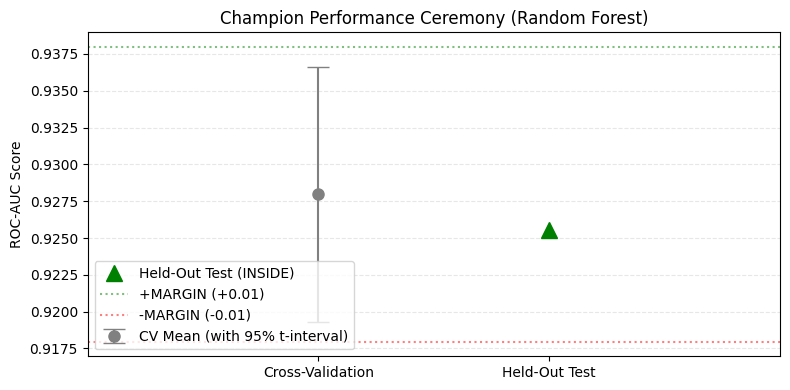

In [26]:
def build_champion(model_name):
    """Recreates the champion pipeline using the preprocessor and tuned hyperparameters."""
    preprocessor = build_preprocessor(X_train)
    if model_name == 'Random Forest':
        # Best parameters: {'max_depth': 5, 'max_features': 0.5, 'n_estimators': 200}
        classifier = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            max_features=0.5,
            class_weight='balanced',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    elif model_name == 'Gradient Boosting':
        # Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
        classifier = GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=RANDOM_SEED
        )
    elif model_name == 'LASSO':
        classifier = LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=1,
            class_weight='balanced',
            random_state=RANDOM_SEED
        )
    else:
        classifier = LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=RANDOM_SEED
        )

    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

# Instantiate and fit champion on X_train
champion_pipe = build_champion(model_choice)
champion_pipe.fit(X_train, y_train)

# Compute holdout ROC-AUC
holdout_probs = champion_pipe.predict_proba(X_holdout)[:, 1]
holdout_auc = roc_auc_score(y_holdout, holdout_probs)

# Extract champion's CV stats from the results summary table
champ_row = results[results['Model'] == model_choice].iloc[0]
cv_mean = champ_row['roc_auc_mean']
cv_sd = champ_row['roc_auc_sd']

# Calculate descriptive interval as context
hw, bounds = ci95(cv_mean, cv_sd, k=5)

# Compare performance gap to margin
gap = holdout_auc - cv_mean

if abs(gap) <= MARGIN:
    label = "INSIDE"
    point_color = "green"
    marker_style = "^"
elif gap > MARGIN:
    label = "ABOVE"
    point_color = "blue"
    marker_style = "^"
else:
    label = "BELOW"
    point_color = "red"
    marker_style = "v"

print("--- Step 8: Champion Evaluation Ceremony ---")
print(f"Champion Model: '{model_choice}'")
print(f"Cross-Validated CV Mean: {cv_mean:.4f} (95% CI Context: {bounds[0]:.4f} to {bounds[1]:.4f})")
print(f"Held-Out Test ROC-AUC: {holdout_auc:.4f}")
print(f"Performance Gap: {gap:+.4f} (Margin: {MARGIN:.2f})")
print(f"Ceremony Label: {label}")

# Recreate Ceremony Plot
plt.figure(figsize=(8, 4))
# Plot CV Mean with its descriptive interval as a grey error bar
plt.errorbar(
    [0],
    [cv_mean],
    yerr=[hw],
    fmt='o',
    color='grey',
    ecolor='grey',
    capsize=8,
    markersize=8,
    label='CV Mean (with 95% t-interval)'
)

# Plot the held-out test score
plt.plot(
    [0.1],
    [holdout_auc],
    marker=marker_style,
    color=point_color,
    markersize=12,
    linestyle='None',
    label=f'Held-Out Test ({label})'
)

# Plot dotted interval bounds and margin boundaries
plt.axhline(cv_mean + MARGIN, color='green', linestyle=':', alpha=0.5, label=f'+MARGIN (+{MARGIN:.2f})')
plt.axhline(cv_mean - MARGIN, color='red', linestyle=':', alpha=0.5, label=f'-MARGIN (-{MARGIN:.2f})')

plt.xlim(-0.1, 0.2)
plt.xticks([0, 0.1], ['Cross-Validation', 'Held-Out Test'])
plt.ylabel('ROC-AUC Score')
plt.title(f'Champion Performance Ceremony ({model_choice})', fontsize=12)
plt.legend(loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

## Step 9 — Final training on the full (merged) training data

With the champion chosen and the held-out sanity check recorded, we **merge the training and held-out test splits back into the full `train.csv`** and refit the champion on all of it — squeezing out every labeled row before predicting the competition test set. We rebuild the winning pipeline from `model_choice`, fit it on `X_full, y_full`, then persist it with `joblib` (nb02) so a teammate — or a grader — can reload and reproduce predictions without retraining.

> 💡 **Gemini Prompt:** "Reuse `build_champion(model_choice)` from Step 8 to rebuild the champion pipeline, refit it on the merged full training data `X_full, y_full`, then `joblib.dump` it to `artifacts/champion_pipeline.joblib` and print the file size."
>
> **After running, verify:**
> - The artifact file is written and its size prints in KB/MB.
> - The pipeline matches `model_choice` from Step 7 and is now fit on every labeled row.

In [28]:
import os
import joblib

# Rebuild the champion pipeline using build_champion and model_choice
final_pipeline = build_champion(model_choice)

# Refit on the merged full training data
final_pipeline.fit(X_full, y_full)

# Ensure artifacts directory exists
os.makedirs('artifacts', exist_ok=True)

# Persist pipeline artifact
artifact_path = 'artifacts/champion_pipeline.joblib'
joblib.dump(final_pipeline, artifact_path)

# Calculate and print file size
file_size_bytes = os.path.getsize(artifact_path)
file_size_kb = file_size_bytes / 1024

print("--- Step 9: Final Training on Merged Data ---")
print(f"Champion Model Selected: '{model_choice}'")
print(f"Pipeline fitted successfully on entire dataset with shape {X_full.shape}")
print(f"Pipeline serialized and saved to: {artifact_path}")
print(f"Artifact File Size: {file_size_kb:.2f} KB")

--- Step 9: Final Training on Merged Data ---
Champion Model Selected: 'Random Forest'
Pipeline fitted successfully on entire dataset with shape (15000, 13)
Pipeline serialized and saved to: artifacts/champion_pipeline.joblib
Artifact File Size: 1047.84 KB


## Step 10 — Predict on the competition test set and export `submission.csv`

We reload the saved pipeline (the way a grader would) and run it on the **unlabeled** `test.csv`. This is the one place the test file is touched — and it is a **production prediction, not a model evaluation**: the file has no labels, so we cannot and do not score it. The `submission.csv` must have exactly the two columns the leaderboard expects: the row identifier and the predicted probability of `Exited`.

> 💡 **Gemini Prompt:** "Reload the pipeline from `ARTIFACT_PATH`. Detect the id column in `df_test_kaggle` (one of `id`, `CustomerId`, `RowNumber`). Call `predict_proba` on the test features and build a DataFrame with columns `[id, Exited]` where `Exited` is the class-1 probability. Save it as `submission.csv` with `index=False` and print the head."
>
> **After running, verify:**
> - `submission.csv` row count equals `df_test_kaggle` row count.
> - The `Exited` column is a float in [0, 1], not 0/1.

In [29]:
import joblib
import pandas as pd

# 1. Reload the champion pipeline from the artifact
artifact_path = 'artifacts/champion_pipeline.joblib'
final_model = joblib.load(artifact_path)

# 2. Detect the id column in df_test_kaggle
id_column = None
for col in ['id', 'CustomerId', 'RowNumber']:
    if col in df_test_kaggle.columns:
        id_column = col
        break

if id_column is None:
    raise ValueError("Could not detect a valid id column ('id', 'CustomerId', 'RowNumber') in the test set.")

# 3. Call predict_proba on the test features and retrieve the class-1 probabilities
test_probabilities = final_model.predict_proba(df_test_kaggle)[:, 1]

# 4. Build submission DataFrame
submission = pd.DataFrame({
    id_column: df_test_kaggle[id_column].astype(int),
    'Exited': test_probabilities
})

# 5. Save to submission.csv
submission_path = 'submission.csv'
submission.to_csv(submission_path, index=False)

# 6. Safety check assertions
assert len(submission) == len(df_test_kaggle), f"Error: Row count mismatch! Expected {len(df_test_kaggle)} rows."
assert submission['Exited'].isna().sum() == 0, "Error: Submission contains NaN values!"
assert submission['Exited'].between(0.0, 1.0).all(), "Error: Predicted probabilities must lie within [0, 1]."

print("--- Step 10: Submission Export ---")
print(f"Submission file successfully saved to: {submission_path}")
print(f"Total prediction rows: {len(submission)}")
print(f"Missing values in predictions: {submission['Exited'].isna().sum()}")
print("\nFirst 5 rows of submission.csv:")
print(submission.head())

--- Step 10: Submission Export ---
Submission file successfully saved to: submission.csv
Total prediction rows: 10000
Missing values in predictions: 0

First 5 rows of submission.csv:
      id  Exited
0  15000   0.837
1  15001   0.818
2  15002   0.085
3  15003   0.176
4  15004   0.752


## 📝 PAUSE-AND-DO Exercise 2 — File the Submission (10 minutes)

**Task:** Confirm the `submission.csv` produced in Step 9 is leaderboard-ready, then upload it.

**Checklist:**

- [ ] `submission.csv` has the exact column names the competition page lists (case-sensitive).
- [ ] Row count matches the `test.csv` row count.
- [ ] The predicted-probability column is a float in `[0, 1]`, not 0/1.
- [ ] No `NaN` rows — `submission.isna().sum().sum() == 0`.
- [ ] The first three rows look like `(id, probability)` pairs you would expect.

Once those five checks pass, upload `submission.csv` to the Kaggle leaderboard.

## Step 99 — Reporting and reproducibility

**Executive summary (template):** dropped identifier columns (`RowNumber`, `CustomerId`, `Surname`); compared a logistic baseline against a tuned LASSO, Random Forest, and Gradient Boosting; selected the champion with the paired-difference → parsimony rule from nb14, comparing the top two models fold by fold against the practical-equivalence margin `MARGIN = 0.01` declared in Step 0.

**Assumptions:** median/most-frequent imputation; one-hot encoding with `handle_unknown='ignore'`; `class_weight='balanced'`; 5-fold stratified CV; Student's-t descriptive intervals reported as approximate 95% intervals (`stats.t.ppf(0.975, df=4)`), read as fold spread rather than as certainty about true performance; `RANDOM_SEED = 474`.

**How to run:**
- Place `train.csv` and `test.csv` at `DATA_DIR`.
- Run all cells top to bottom.
- Artifacts: `artifacts/champion_pipeline.joblib`, `submission.csv`, `requirements.txt`.

> 💡 **Gemini Prompt:** "Write a `requirements.txt` capturing the installed versions of pandas, numpy, scikit-learn, scipy, matplotlib, and joblib so the environment is reproducible. Read each version at runtime (e.g., `pd.__version__`) and print the file contents."

In [30]:
import pandas as pd
import numpy as np
import sklearn
import scipy
import matplotlib
import joblib

# Create requirements list at runtime
requirements = [
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"scipy=={scipy.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"joblib=={joblib.__version__}"
]

# Write to requirements.txt
requirements_path = 'requirements.txt'
with open(requirements_path, 'w') as f:
    for req in requirements:
        f.write(req + '\n')

print("--- Step 99: Environment Requirements ---")
print(f"Successfully wrote the following specifications to: {requirements_path}\n")
with open(requirements_path, 'r') as f:
    print(f.read())

--- Step 99: Environment Requirements ---
Successfully wrote the following specifications to: requirements.txt

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
joblib==1.6.0



## Wrap-Up — Key Takeaways

1. **One workflow, nine steps.** Setup → load → EDA → feature engineering → baseline → richer models → comparison → selection → final fit → submission. Every case-competition deliverable lives somewhere on this spine; if you can name the step, you can debug the failure.
2. **Compare models fold by fold, not error bar against error bar.** The 5-fold CV ROC-AUC and its Student's-*t* interval describe how far each candidate moved across folds; the promotion call comes from the *paired* comparison — same `cv_strat` folds, subtract per fold, then read one of three outcomes. Five differences sharing one sign with a mean over the `MARGIN = 0.01` declared in Step 0 promote the top model; mixed signs mean the folds disagree and the comparison names no winner, so the simpler model stays; one sign with a mean under the margin means the two are practically equivalent, and the simpler model wins by parsimony.
3. **Selection is a documented decision, not a leaderboard reflex.** Step 7 applies nb14's paired-difference rule against the margin declared in Step 0 and writes the rationale in plain English. A model you can defend in three sentences beats a slightly higher public-leaderboard score you cannot explain.
4. **Split, select, check, then merge.** One 80/20 split lets cross-validation pick the champion on the training portion and gives an unbiased held-out check before you commit. Only then do you merge both splits, refit on the entire `train.csv`, and touch the unlabeled `test.csv` — a production prediction, not a model evaluation.
5. **The submission file is a contract.** Exact column names, one probability per test row, no `NaN`. Persist the fitted pipeline with `joblib` so a teammate — or a grader — can reproduce your `submission.csv` in seconds.

> **A question that often comes up here:** *"What if my Kaggle score is much worse than my cross-validated AUC?"* Three usual culprits, in order of frequency: (1) the train and test files have different column distributions ("covariate shift") — compare numeric means and category counts; (2) preprocessing transformed a column on training data that behaves differently on test data — check that the pipeline's transformed test matrix has the same shape as the training transform; or (3) a leaky feature inflated your CV folds — if a single feature looks too good to be true, it probably is.


## Participation Assignment Submission Instructions

1. **Complete both PAUSE-AND-DO exercises**.
2. **Run all cells**.
3. **Save with output** and submit `nb18_competition_workflow_<your_lastname>.ipynb` to Brightspace.
4. **Upload `submission.csv`** to the Kaggle leaderboard.

### Next Step:

- **Notebook 19** — Special topic: deep learning (Wed Oct 21), then **Notebook 17** — Data communication + the research poster (Mon Oct 26, the last lecture of the course)

**Bibliography**
- scikit-learn User Guide — [Model persistence](https://scikit-learn.org/stable/model_persistence.html)


<center>

# Thank you!

</center>
